# Chapter 10: Regularization & Cross-Validation

## Learning Objectives
After completing this chapter, you will be able to:
- Explain why a single train-test split is not a reliable way to choose hyperparameters
- Use k-fold cross-validation to evaluate a model and to tune its hyperparameters
- Use `GridSearchCV` to automate the search for the best hyperparameters
- Explain how Ridge and Lasso regression prevent overfitting by penalizing large coefficients
- Choose the regularization strength $\alpha$ with cross-validation

This chapter gives you two tools that you will use with almost every model from now on!

In [1]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# Lasso can warn that it needs more iterations for very small alphas (see section 10.3.2).
# The results are still usable, so we hide these warnings to keep the output readable.
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

## 10.1 Introduction & Motivation

Remember Chapter 3? We fitted polynomials of increasing degree and saw that a very flexible model can follow the training data almost perfectly, while making terrible predictions on new data. This is **overfitting**. We solved it by trying many degrees and picking the one with the lowest **test** MSE.

That approach left us with two open problems:

1. **How do we choose hyperparameters honestly?** Every time we look at the test set to make a choice, the test set becomes part of our training process. It can then no longer tell us how well the model does on truly *new* data. The solution is **cross-validation**.
2. **Can we use a flexible model without overfitting?** Instead of limiting the degree of the polynomial, we can let the model be flexible but *punish* it for becoming too wild. This is called **regularization**.

**Why is this important?**
You have already met many hyperparameters in this course, and all of them need to be chosen somehow:
- The polynomial degree (Chapter 3)
- The maximum depth of a decision tree (Chapter 5)
- The number of neighbors $k$ (Chapter 6)
- The number of principal components (Chapter 9)

Cross-validation is *the* standard way to choose all of them. Regularization is used in almost every modern model, from linear regression to deep neural networks.

## 10.2 Problem Setting

We'll reuse the non-linear dataset from Chapter 3, this time with 40 data points. A quarter of the data is kept aside as a test set.

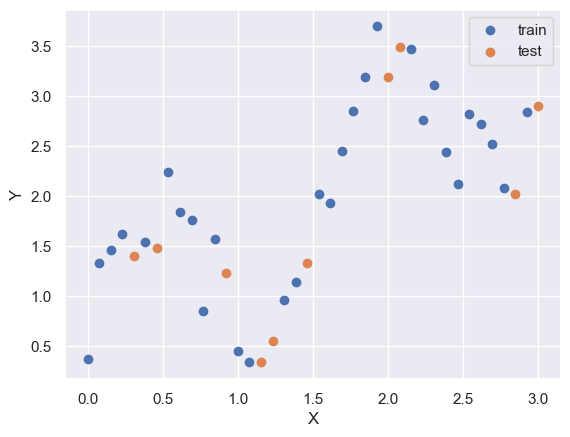

In [2]:
x = np.linspace(0, 3, 40)
rng = np.random.RandomState(42)
y = np.sin(4 * x) + x + rng.uniform(size=len(x))
X = x[:, np.newaxis]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

plt.scatter(X_train, y_train, label='train')
plt.scatter(X_test, y_test, label='test')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

Let's fit a very flexible model: a polynomial of degree 15.

**New tool: pipelines.** Instead of calling `PolynomialFeatures` and `LinearRegression` separately (as in Chapter 3), we chain all steps together with `make_pipeline`. The pipeline behaves like one single model with `.fit()` and `.predict()`. We also add a `StandardScaler`, because the polynomial features have wildly different scales ($x$ is at most 3, but $x^{15}$ is over 14 million!). We'll see later why scaling is so important.

Train MSE: 0.04183376060529391
Test MSE:  0.8543691900160241


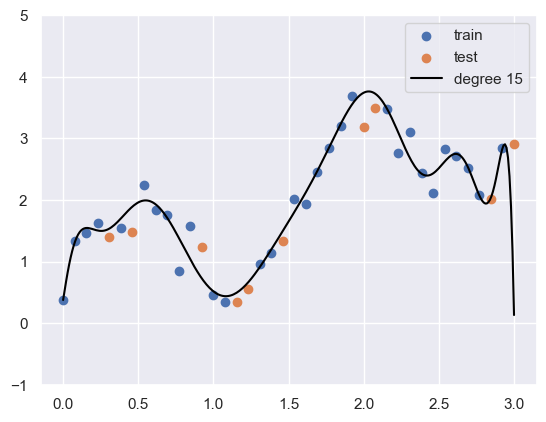

In [3]:
model = make_pipeline(PolynomialFeatures(degree=15, include_bias=False), StandardScaler(), LinearRegression())
model.fit(X_train, y_train)

print('Train MSE:', mean_squared_error(y_train, model.predict(X_train)))
print('Test MSE: ', mean_squared_error(y_test, model.predict(X_test)))

x_plot = np.linspace(0, 3, 300).reshape(-1, 1)
plt.scatter(X_train, y_train, label='train')
plt.scatter(X_test, y_test, label='test')
plt.plot(x_plot, model.predict(x_plot), color='black', label='degree 15')
plt.ylim(-1, 5)
plt.legend()
plt.show()

The curve wiggles to pass close to every training point, so the training MSE is tiny while the test MSE is much larger. A classic case of overfitting!

Let's look at the coefficients the model learned. The last step of the pipeline is the `LinearRegression`, which we can reach with `model[-1]`:

In [4]:
model[-1].coef_

array([ 1.40082732e+01, -2.16192181e+01, -6.44115737e+03,  1.25403907e+05,
       -1.17639084e+06,  6.83024855e+06, -2.70803119e+07,  7.68557418e+07,
       -1.59339438e+08,  2.41963947e+08, -2.65909131e+08,  2.05494967e+08,
       -1.05723206e+08,  3.24568396e+07, -4.49222129e+06])

**Key insight:** The coefficients are *enormous* (some are in the millions) and have alternating signs. The model makes huge positive and negative contributions that almost cancel each other out, just to bend the curve through every training point. Keep this in mind: **overfitting often comes with very large coefficients.**

There is a second problem. How much can we trust a test MSE that is based on a single split? Let's train the *exact same* model type (degree 5) on 10 different random train-test splits of the same data:

In [5]:
for state in range(10):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=state)
    model = make_pipeline(PolynomialFeatures(degree=5, include_bias=False), StandardScaler(), LinearRegression())
    model.fit(X_tr, y_tr)
    print('random_state =', state, '-> test MSE:', round(mean_squared_error(y_te, model.predict(X_te)), 3))

random_state = 0 -> test MSE: 0.202
random_state = 1 -> test MSE: 0.116
random_state = 2 -> test MSE: 0.108
random_state = 3 -> test MSE: 0.178
random_state = 4 -> test MSE: 0.214
random_state = 5 -> test MSE: 0.478
random_state = 6 -> test MSE: 0.116
random_state = 7 -> test MSE: 0.142
random_state = 8 -> test MSE: 0.205
random_state = 9 -> test MSE: 0.178


##### Question 1: All 10 test MSE values above come from the same model type trained on the same data. Why are they so different? What does this mean for the way we picked the best polynomial degree in Chapter 3?

**Hints:**
- How many points are in each test set?
- Do some splits get "easier" or "harder" test points than others?
- In Chapter 3 we tried 40 degrees and kept the one with the lowest test MSE. Is that test MSE still an honest estimate of performance on new data?

**Your answer here:**

## 10.3 Model

### 10.3.1 Cross-Validation

**Step 1: Lock away the test set.** The test set is only used *once*, at the very end, to report the final performance. It is never used to make choices.

**Step 2: Create validation sets from the training data.** To compare hyperparameters, we need data the model has not seen. We could split the training set again into a smaller training set and a **validation set**. But then we have the same problem as above: one small validation set gives a noisy score, and we "waste" data.

**Step 3: k-fold cross-validation.** Instead of one validation set, we make $k$ of them:
1. Split the training data into $k$ equal parts, called **folds** (for example $k = 5$)
2. Train the model on $k - 1$ folds and compute the score on the remaining fold
3. Repeat this $k$ times, so that every fold is used as the validation fold exactly once
4. The **cross-validation score** is the average of the $k$ scores

**Why does this work better?**
- Every training point is used for validation exactly once, so no data is wasted
- Averaging $k$ scores removes much of the "luck" of a single split
- The spread (standard deviation) of the $k$ scores tells us how stable the model is

The picture below shows 5-fold cross-validation:

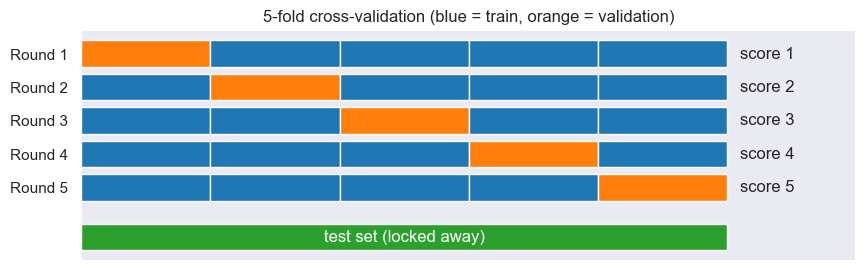

In [6]:
# Visualize 5-fold cross-validation: each row is one round of training
fig, ax = plt.subplots(figsize=(10, 3))
n_folds = 5
for round_nr in range(n_folds):
    for fold in range(n_folds):
        color = 'tab:orange' if fold == round_nr else 'tab:blue'
        ax.barh(round_nr, 1, left=fold, color=color, edgecolor='white')
    ax.text(n_folds + 0.1, round_nr, f'score {round_nr + 1}', va='center')
ax.barh(n_folds + 0.5, n_folds, color='tab:green', edgecolor='white')
ax.text(n_folds / 2, n_folds + 0.5, 'test set (locked away)', ha='center', va='center', color='white')
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f'Round {i + 1}' for i in range(n_folds)])
ax.set_xticks([])
ax.invert_yaxis()
ax.set_xlim(0, n_folds + 1)
ax.grid(False)
ax.set_title('5-fold cross-validation (blue = train, orange = validation)')
plt.show()

In scikit-learn, `KFold` decides how the folds are made, and `cross_val_score` does all the training and scoring for us. Notice that we **only pass the training data**: the test set stays locked away.

**Note on the scoring:** scikit-learn always assumes that a *higher* score is better. For an error like the MSE, lower is better, so scikit-learn returns the *negative* MSE (`'neg_mean_squared_error'`). We simply put a minus sign in front to get the normal MSE back.

In [7]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(PolynomialFeatures(degree=5, include_bias=False), StandardScaler(), LinearRegression())

scores = cross_val_score(model, X_train, y_train, cv=kfold, scoring='neg_mean_squared_error')
print('MSE per fold:', np.round(-scores, 3))
print('Mean CV MSE: ', round(-scores.mean(), 3))
print('Std CV MSE:  ', round(scores.std(), 3))

MSE per fold: [0.107 0.218 0.4   0.352 0.141]
Mean CV MSE:  0.244
Std CV MSE:   0.115


**Why we use a pipeline here:** `cross_val_score` fits the *whole pipeline* again in every round. That means the `StandardScaler` only learns the mean and standard deviation from the training folds, and never "sees" the validation fold. If we scaled all the data beforehand, information from the validation fold would leak into training. This is called **data leakage**, and it makes cross-validation scores too optimistic.

**Why `shuffle=True`?** Our data was created in order from small to large $x$. Without shuffling, the first fold would contain only the smallest $x$ values, and the model would have to extrapolate. Shuffling makes every fold a fair sample of the data.

##### Question 2: Use 5-fold cross-validation to find the best polynomial degree between 1 and 15, using **only the training set**. Plot the train MSE and the CV MSE against the degree (just like we did in Chapter 3). Which degree do you choose? Finally, train that model on the full training set and evaluate it **once** on the test set.

**Hints:**
- Loop over the degrees and build the same pipeline as above inside the loop
- Use `cross_val_score(...)` with `cv=kfold` for the CV MSE
- For the train MSE, fit the pipeline on `X_train` and predict `X_train`
- The CV MSE of the highest degrees explodes. Use `plt.yscale('log')` to keep the plot readable

In [8]:
# Your code here


**Your answer here:**

Writing this loop every time is a lot of work. `GridSearchCV` does exactly the same thing for us: it tries every value in a **parameter grid**, runs cross-validation for each one and remembers the best.

**Naming convention:** to reach a parameter *inside* a pipeline, use the name of the step in lowercase, two underscores, and the parameter name. For example `polynomialfeatures__degree`.

In [9]:
model = make_pipeline(PolynomialFeatures(include_bias=False), StandardScaler(), LinearRegression())
param_grid = {'polynomialfeatures__degree': range(1, 16)}

grid = GridSearchCV(model, param_grid, cv=kfold, scoring='neg_mean_squared_error')
grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best CV MSE:    ', -grid.best_score_)
print('Test MSE:       ', mean_squared_error(y_test, grid.predict(X_test)))

Best parameters: {'polynomialfeatures__degree': 6}
Best CV MSE:     0.19843803992233636
Test MSE:        0.2647574360454305


**Good to know:** after the search, `GridSearchCV` automatically retrains the best model on the *whole* training set (this is called `refit`). That's why we can call `grid.predict()` directly.

### 10.3.2 Model Estimation: Regularization

Cross-validation helps us choose a model that does not overfit. Regularization attacks overfitting from a different angle: we change **what the model tries to minimize**.

Remember that overfitting models have huge coefficients. So let's make large coefficients *expensive*. An ordinary linear regression finds the coefficients $\beta$ that minimize the error:

$$\text{minimize} \quad \text{MSE}$$

A **regularized** regression adds a penalty for large coefficients:

| Model | What it minimizes | Penalty name |
|---|---|---|
| Linear Regression | $\text{MSE}$ | none |
| **Ridge** Regression | $\text{MSE} + \alpha \sum_j \beta_j^2$ | L2 penalty |
| **Lasso** Regression | $\text{MSE} + \alpha \sum_j \lvert\beta_j\rvert$ | L1 penalty |

*(scikit-learn's exact formulas differ by a constant factor, but the idea is the same.)*

**Think of it as a budget:** the model wants to fit the data well, but every unit of coefficient size costs something. It will only use a large coefficient if it really pays off in a lower error.

**The hyperparameter $\alpha$ (alpha)** controls how expensive large coefficients are:
- $\alpha = 0$: no penalty, this is just ordinary linear regression (risk of overfitting)
- small $\alpha$: coefficients are gently pushed towards zero
- large $\alpha$: all coefficients are forced close to zero and the model becomes a flat line (risk of underfitting)

So $\alpha$ is a hyperparameter, and we already know how to choose it: **cross-validation!**

**Important: always scale your features before regularizing.** The penalty treats all coefficients the same. If one feature is measured in grams and another in kilograms, their coefficients have completely different sizes for the same effect, and the penalty would be unfair. The `StandardScaler` puts all features on the same scale. (The intercept $\beta_0$ is never penalized.)

The function below works just like `poly_test` from Chapter 3. It builds a degree 15 polynomial model, but uses **Ridge** regression with a regularization strength `alpha` of your choice, and plots the result.

alpha = 0.001
	Train MSE: 0.151
	Test MSE:  0.141
	Largest coefficient: 17.74


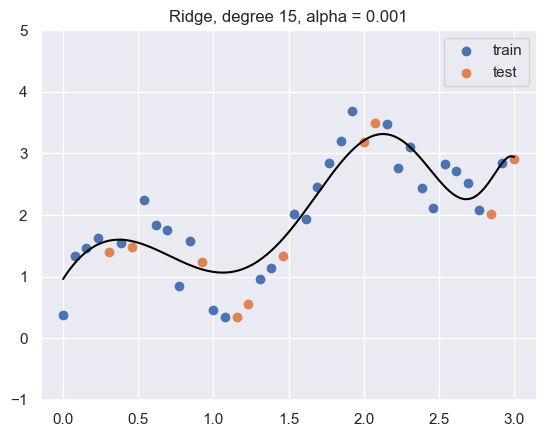

In [10]:
def ridge_test(alpha):
    model = make_pipeline(PolynomialFeatures(degree=15, include_bias=False), StandardScaler(), Ridge(alpha=alpha))
    model.fit(X_train, y_train)
    print('alpha =', alpha)
    print('\tTrain MSE:', round(mean_squared_error(y_train, model.predict(X_train)), 3))
    print('\tTest MSE: ', round(mean_squared_error(y_test, model.predict(X_test)), 3))
    print('\tLargest coefficient:', round(np.abs(model[-1].coef_).max(), 2))
    plt.scatter(X_train, y_train, label='train')
    plt.scatter(X_test, y_test, label='test')
    plt.plot(x_plot, model.predict(x_plot), color='black')
    plt.ylim(-1, 5)
    plt.title(f'Ridge, degree 15, alpha = {alpha}')
    plt.legend()
    plt.show()

ridge_test(0.001)

##### Question 3: Use `ridge_test` to try the values $\alpha$ = 0.000001, 0.001, 1 and 100. What happens to the curve, the train MSE, the test MSE and the largest coefficient as $\alpha$ grows? Which value looks best?

**Hints:**
- Compare the largest coefficient with the coefficients of the unregularized degree 15 model from section 10.2
- Which value of $\alpha$ overfits? Which one underfits?

In [11]:
# Your code here


**Your answer here:**

**Lasso** works just like Ridge, but uses the *absolute value* of the coefficients as the penalty. This small change has a big consequence: Lasso can set coefficients **exactly to zero**. A coefficient of zero means that the feature is not used at all, so Lasso automatically performs **feature selection**. Ridge only makes coefficients *small*, never exactly zero.

**Good to know:** Lasso finds its coefficients step by step (iteratively). For very small values of $\alpha$, it can need a lot of steps, which is why we set `max_iter=100000`. If it still hasn't finished, scikit-learn shows a `ConvergenceWarning`. We have hidden these warnings in the first cell of this notebook.

Let's compare the coefficients of the three models (all degree 15). Look carefully at the scale of each y-axis!

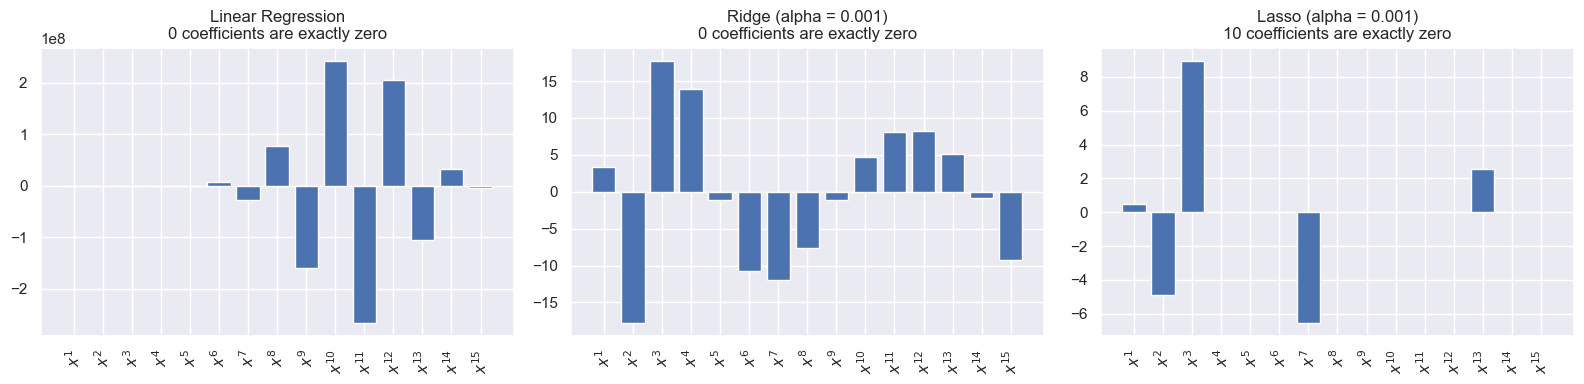

In [12]:
feature_names = ['$x^{' + str(i) + '}$' for i in range(1, 16)]
models = {
    'Linear Regression': LinearRegression(),
    'Ridge (alpha = 0.001)': Ridge(alpha=0.001),
    'Lasso (alpha = 0.001)': Lasso(alpha=0.001, max_iter=100000),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, regressor) in zip(axes, models.items()):
    model = make_pipeline(PolynomialFeatures(degree=15, include_bias=False), StandardScaler(), regressor)
    model.fit(X_train, y_train)
    coefs = model[-1].coef_
    ax.bar(feature_names, coefs)
    ax.set_title(f'{name}\n{np.sum(coefs == 0)} coefficients are exactly zero')
    ax.tick_params(axis='x', labelrotation=90)
plt.tight_layout()
plt.show()

##### Question 4: Count how many of the 15 coefficients Lasso sets exactly to zero for $\alpha$ = 0.00001, 0.0001, 0.001, 0.01 and 0.1. Plot the number of zero coefficients against $\alpha$. What do you notice? For a large $\alpha$, which polynomial terms survive?

**Hints:**
- Use the same pipeline as above with `Lasso(alpha=alpha, max_iter=100000)`
- `np.sum(model[-1].coef_ == 0)` counts the zero coefficients
- Use `plt.xscale('log')`, because the values of $\alpha$ are spread over several orders of magnitude

In [13]:
# Your code here


**Your answer here:**

## 10.4 Model Evaluation

How do we pick the best $\alpha$? With cross-validation, of course! The plot below shows the train MSE and the CV MSE of the degree 15 Ridge model for many values of $\alpha$. This is called a **validation curve**.

**Notice:** in Chapter 3 the x-axis went from *simple* to *complex* (increasing degree). Here, a larger $\alpha$ means a *simpler* model, so the plot is mirrored: overfitting is on the left, underfitting on the right.

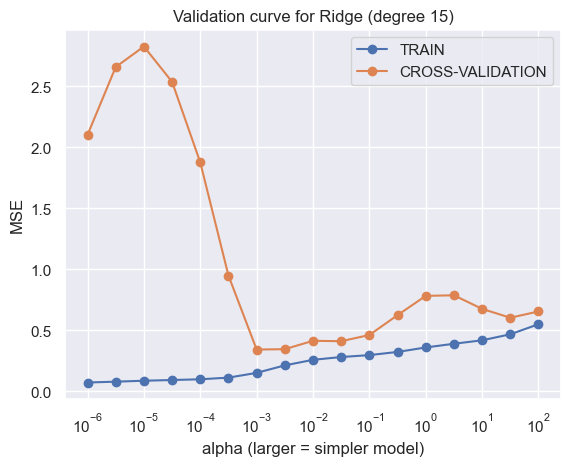

In [14]:
alphas = np.logspace(-6, 2, 17)  # 17 values from 0.000001 to 100, evenly spread on a log scale
train_mse = []
cv_mse = []

for alpha in alphas:
    model = make_pipeline(PolynomialFeatures(degree=15, include_bias=False), StandardScaler(), Ridge(alpha=alpha))
    scores = cross_val_score(model, X_train, y_train, cv=kfold, scoring='neg_mean_squared_error')
    cv_mse.append(-scores.mean())
    model.fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, model.predict(X_train)))

plt.plot(alphas, train_mse, marker='o', label='TRAIN')
plt.plot(alphas, cv_mse, marker='o', label='CROSS-VALIDATION')
plt.xscale('log')
plt.xlabel('alpha (larger = simpler model)')
plt.ylabel('MSE')
plt.title('Validation curve for Ridge (degree 15)')
plt.legend()
plt.show()

##### Question 5: Use `GridSearchCV` to find the best $\alpha$ for both **Ridge** and **Lasso** (degree 15, `kfold` as before). Report the best $\alpha$ and its CV MSE for each model. Then evaluate both best models once on the test set, and plot their curves.

**Hints:**
- For Ridge, search `{'ridge__alpha': np.logspace(-6, 2, 17)}`
- For Lasso, search `{'lasso__alpha': np.logspace(-5, 0, 11)}` and use `Lasso(max_iter=100000)` in the pipeline
- `grid.best_params_`, `grid.best_score_` and `grid.predict()` give you everything you need

In [15]:
# Your code here


**Your answer here:**

##### Question 6: Put the **test MSE** of the following models in one table: the unregularized degree 15 model (section 10.2), the best polynomial degree found with cross-validation (Question 2), and the best Ridge and Lasso models (Question 5). Which model would you choose and why?

**Hints:**
- Create a `pd.DataFrame` with one row per model
- Don't only look at the test MSE: also think about how each model was chosen and how simple it is

In [16]:
# Your code here


**Your answer here:**

## 10.5 Exercises

##### Question 1: See section 10.2
##### Question 2: See section 10.3.1
##### Question 3: See section 10.3.2
##### Question 4: See section 10.3.2
##### Question 5: See section 10.4
##### Question 6: See section 10.4

##### Question 7: In this chapter, we always put the `StandardScaler` *inside* the pipeline. Why is this better than scaling the whole dataset once at the start, before doing cross-validation?

**Hint:** What does the scaler learn from the data when you call `.fit()`? Which data does it see?

**Your answer here:**

##### Question 8: An extreme form of k-fold cross-validation is **Leave-One-Out Cross-Validation (LOOCV)**, where $k$ is equal to the number of training points. How many models would you need to train for our training set of 30 points? What are the advantages and disadvantages of LOOCV?

**Hint:** Think about how much data each model is trained on, and about computation time for a dataset with one million rows.

**Your answer here:**

##### Question 9: Without calling it that, you have already used regularization in earlier chapters! For each of the following hyperparameters, explain how it controls the complexity of the model, and in which direction it makes the model *simpler*:
- `max_depth` of a decision tree (Chapter 5)
- `n_neighbors` ($k$) of k-NN (Chapter 6)
- `C` of `LogisticRegression` (Chapter 4)

**Hint:** Look up the `penalty` and `C` parameters in the scikit-learn documentation of `LogisticRegression`.

**Your answer here:**